# NextGen Project: Late Delivery Risk Prediction

This notebook presents the end-to-end workflow for predicting late deliveries using supply chain data, from data preparation and exploratory analysis to model training, evaluation, and final deployment.


In [ ]:
# 1. IMPORT REQUIRED LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
import joblib


# Scikit-learn: preprocessing and ML
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import randint

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score,
    roc_curve
)

warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Data Acquisition and Loading

This section covers the required libraries and the initial loading of the supply chain dataset into the analysis environment.


In [ ]:
# 2. UPLOAD DATASET
# ==========================================

file_path = "/DataCoSupplyChainDataset.csv"
df = pd.read_csv(file_path, encoding="latin1")
print(f"Dataset loaded successfully: {file_path}")



Dataset loaded successfully: /DataCoSupplyChainDataset.csv


In [ ]:
# 3. DATASET OVERVIEW
# ==========================================

print(f"Number of Rows: {df.shape[0]:,}")
print(f"Number of Columns: {df.shape[1]:,}")

print("\nFirst 5 Rows:")
display(df.head())

Number of Rows: 180,519
Number of Columns: 53

First 5 Rows:


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [ ]:
# 4. COLUMN INFORMATION
# ==========================================

column_info = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Missing Count": df.isna().sum().values,
    "Missing Percentage": (df.isna().mean().values * 100).round(2),
    "Unique Values": df.nunique(dropna=True).values
})

display(column_info)

,Column,Data Type,Non-Null Count,Missing Count,Missing Percentage,Unique Values
0,Type,object,180519,0,0.00,4
1,Days for shipping (real),int64,180519,0,0.00,7
2,Days for shipment (scheduled),int64,180519,0,0.00,4
3,Benefit per order,float64,180519,0,0.00,21998
4,Sales per customer,float64,180519,0,0.00,2927
5,Delivery Status,object,180519,0,0.00,4
6,Late_delivery_risk,int64,180519,0,0.00,2
7,Category Id,int64,180519,0,0.00,51
8,Category Name,object,180519,0,0.00,50
9,Customer City,object,180519,0,0.00,563


## 2. Data Profiling and Cleaning

This stage reviews column structure, identifies missing values, and removes non-predictive or leakage-prone fields before the modeling workflow begins.


In [ ]:
# DROP UNNECESSARY COLUMNS
# ==========================================

columns_to_drop = [
    # Actual delivery information (Data Leakage)
    'Days for shipping (real)',
    'Delivery Status',
    'shipping date (DateOrders)',

    # Order lifecycle information (not available at prediction time)
    'Order Status',

    # Personal and sensitive customer information
    'Customer Email',
    'Customer Fname',
    'Customer Lname',
    'Customer Password',
    'Customer Street',

    # Identifiers (not useful as direct predictive features)
    'Customer Id',
    'Order Customer Id',
    'Order Id',
    'Order Item Id',
    'Order Item Cardprod Id',
    'Product Card Id',
    'Category Id',
    'Product Category Id',
    'Department Id',

    # Redundant or low-value columns
    'Product Description',
    'Sales per customer',
    'Sales',
    'Product Image',
    'Product Status',
    'Customer Zipcode',
    'Order Zipcode',
    'Customer City',
    'Customer Country',
    'Customer State',
    'Latitude',
    'Longitude',
]

# Drop only columns that actually exist
columns_to_drop = [
    col for col in columns_to_drop if col in df.columns
]

df.drop(columns=columns_to_drop, inplace=True)

print(f"Removed {len(columns_to_drop)} columns:")

print(f"\nRemaining columns: {df.shape[1]}")
display(df.head())

Removed 30 columns:

Remaining columns: 23


,Type,Days for shipment (scheduled),Benefit per order,Late_delivery_risk,Category Name,Customer Segment,Department Name,Market,Order City,Order Country,order date (DateOrders),Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Order Item Total,Order Profit Per Order,Order Region,Order State,Product Name,Product Price,Shipping Mode
0,DEBIT,4,91.250000,0,Sporting Goods,Consumer,Fitness,Pacific Asia,Bekasi,Indonesia,1/31/2018 22:56,13.110000,0.04,327.75,0.29,1,314.640015,91.250000,Southeast Asia,Java Occidental,Smart watch,327.75,Standard Class
1,TRANSFER,4,-249.089996,1,Sporting Goods,Consumer,Fitness,Pacific Asia,Bikaner,India,1/13/2018 12:27,16.389999,0.05,327.75,-0.80,1,311.359985,-249.089996,South Asia,Rajastán,Smart watch,327.75,Standard Class
2,CASH,4,-247.779999,0,Sporting Goods,Consumer,Fitness,Pacific Asia,Bikaner,India,1/13/2018 12:06,18.030001,0.06,327.75,-0.80,1,309.720001,-247.779999,South Asia,Rajastán,Smart watch,327.75,Standard Class
3,DEBIT,4,22.860001,0,Sporting Goods,Home Office,Fitness,Pacific Asia,Townsville,Australia,1/13/2018 11:45,22.940001,0.07,327.75,0.08,1,304.809998,22.860001,Oceania,Queensland,Smart watch,327.75,Standard Class
4,PAYMENT,4,134.210007,0,Sporting Goods,Corporate,Fitness,Pacific Asia,Townsville,Australia,1/13/2018 11:24,29.500000,0.09,327.75,0.45,1,298.250000,134.210007,Oceania,Queensland,Smart watch,327.75,Standard Class


In [ ]:
# CHECK DUPLICATE / SIMILAR COLUMNS
# ==========================================

# 1. Exact duplicate columns
duplicate_columns = []

for i in range(len(df.columns)):
    for j in range(i + 1, len(df.columns)):

        col1 = df.columns[i]
        col2 = df.columns[j]

        if df[col1].equals(df[col2]):
            duplicate_columns.append((col1, col2))

print("EXACT DUPLICATE COLUMNS:")
for col1, col2 in duplicate_columns:
    print(f"{col1} == {col2}")

if not duplicate_columns:
    print("No exact duplicate columns found.")


# 2. Highly correlated numerical columns
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr().abs()

high_correlation = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):

        col1 = correlation_matrix.columns[i]
        col2 = correlation_matrix.columns[j]

        corr_value = correlation_matrix.iloc[i, j]

        if corr_value >= 0.90:
            high_correlation.append(
                (col1, col2, round(corr_value, 3))
            )

print("\nHIGHLY CORRELATED NUMERICAL COLUMNS:")
for col1, col2, corr in high_correlation:
    print(f"{col1} <-> {col2}: {corr}")

EXACT DUPLICATE COLUMNS:
Benefit per order == Order Profit Per Order
Order Item Product Price == Product Price

HIGHLY CORRELATED NUMERICAL COLUMNS:
Benefit per order <-> Order Profit Per Order: 1.0
Order Item Product Price <-> Product Price: 1.0


In [ ]:
columns_to_drop = [
    'Order Profit Per Order',
    'Product Price',
]

df.drop(columns=columns_to_drop, inplace=True)

print("Remaining columns:", df.shape[1])

Remaining columns: 21


In [ ]:
columns_to_check = [
    'Category Name',
    'Product Name',
    'Department Name',
    'Market',
    'Order Region',
    'Order Country',
    'Order State',
    'Order City'
]

for col in columns_to_check:
    if col in df.columns:
        print(f"{col} ==> Unique values: {df[col].nunique()}\n")

Category Name ==> Unique values: 50

Product Name ==> Unique values: 118

Department Name ==> Unique values: 11

Market ==> Unique values: 5

Order Region ==> Unique values: 23

Order Country ==> Unique values: 164

Order State ==> Unique values: 1089

Order City ==> Unique values: 3597



In [ ]:
# Drop columns bec it is unnecessary info , and will difficult the encoding due to high unique values
columns_to_drop = [
    'Product Name',
    'Order State',
    'Order City'
]

df.drop(columns=columns_to_drop, inplace=True)

print("Remaining columns:", df.shape[1])

Remaining columns: 18


In [ ]:
# 5. STATISTICAL DESCRIPTION
# ==========================================

print("Numerical Features Description:")
display(df.describe().T)

print("\nCategorical Features Description:")
display(df.describe(include=["object"]).T)

Numerical Features Description:


,count,mean,std,min,25%,50%,75%,max
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.00000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180519.0,21.974989,104.433526,-4274.97998,7.000000,31.520000,64.800003,911.799988
Late_delivery_risk,180519.0,0.548291,0.497664,0.00000,0.000000,1.000000,1.000000,1.000000
Order Item Discount,180519.0,20.664741,21.800901,0.00000,5.400000,14.000000,29.990000,500.000000
Order Item Discount Rate,180519.0,0.101668,0.070415,0.00000,0.040000,0.100000,0.160000,0.250000
Order Item Product Price,180519.0,141.232550,139.732492,9.99000,50.000000,59.990002,199.990005,1999.989990
Order Item Profit Ratio,180519.0,0.120647,0.466796,-2.75000,0.080000,0.270000,0.360000,0.500000
Order Item Quantity,180519.0,2.127638,1.453451,1.00000,1.000000,1.000000,3.000000,5.000000
Order Item Total,180519.0,183.107609,120.043670,7.49000,104.379997,163.990005,247.399994,1939.989990



Categorical Features Description:


,count,unique,top,freq
Type,180519,4,DEBIT,69295
Category Name,180519,50,Cleats,24551
Customer Segment,180519,3,Consumer,93504
Department Name,180519,11,Fan Shop,66861
Market,180519,5,LATAM,51594
Order Country,180519,164,Estados Unidos,24840
order date (DateOrders),180519,65752,1/4/2017 2:28,5
Order Region,180519,23,Central America,28341
Shipping Mode,180519,4,Standard Class,107752


## 3. Exploratory Data Analysis

This section examines feature distributions, target balance, and the relationships between variables and late-delivery risk.


In [ ]:
# 6. CATEGORICAL FEATURES: UNIQUE VALUES
# ==========================================

print("\n" + "=" * 60)
print("CATEGORICAL FEATURES AND THEIR VALUES")
print("=" * 60)

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_columns:
    print(f"\n{col}")
    print(f"Unique values: {df[col].nunique(dropna=True)}")
    print(df[col].value_counts(dropna=False).head(15))


CATEGORICAL FEATURES AND THEIR VALUES

Type
Unique values: 4
Type
DEBIT       69295
TRANSFER    49883
PAYMENT     41725
CASH        19616
Name: count, dtype: int64

Category Name
Unique values: 50
Category Name
Cleats                  24551
Men's Footwear          22246
Women's Apparel         21035
Indoor/Outdoor Games    19298
Fishing                 17325
Water Sports            15540
Camping & Hiking        13729
Cardio Equipment        12487
Shop By Sport           10984
Electronics              3156
Accessories              1780
Golf Balls               1475
Girls' Apparel           1201
Golf Gloves              1070
Trade-In                  974
Name: count, dtype: int64

Customer Segment
Unique values: 3
Customer Segment
Consumer       93504
Corporate      54789
Home Office    32226
Name: count, dtype: int64

Department Name
Unique values: 11
Department Name
Fan Shop              66861
Apparel               48998
Golf                  33220
Footwear              14525
Outdoors

Target Column: Late_delivery_risk

Target Distribution:


,Count
Late_delivery_risk,
1,98977
0,81542



Target Percentage:


,Percentage
Late_delivery_risk,
1,54.83
0,45.17


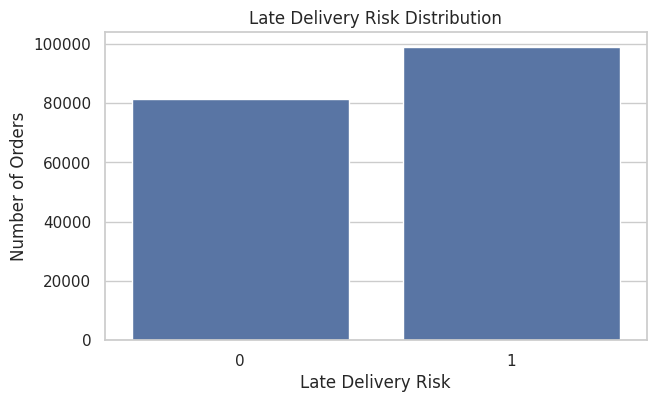

In [ ]:
# EDA
# 7. TARGET VARIABLE ANALYSIS
# ==========================================

target = 'Late_delivery_risk'

if target not in df.columns:
    raise ValueError(f"{target} not found in dataframe")

print(f"Target Column: {target}")
print("\nTarget Distribution:")
display(df[target].value_counts().to_frame("Count"))

print("\nTarget Percentage:")
display(
    (df[target].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("Percentage"))

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=target)
plt.title("Late Delivery Risk Distribution")
plt.xlabel("Late Delivery Risk")
plt.ylabel("Number of Orders")
plt.show()

TARGET DISTRIBUTION


,Count,Percentage
Late_delivery_risk,,
0,81542,45.17
1,98977,54.83


Overall Late Delivery Rate: 54.83%


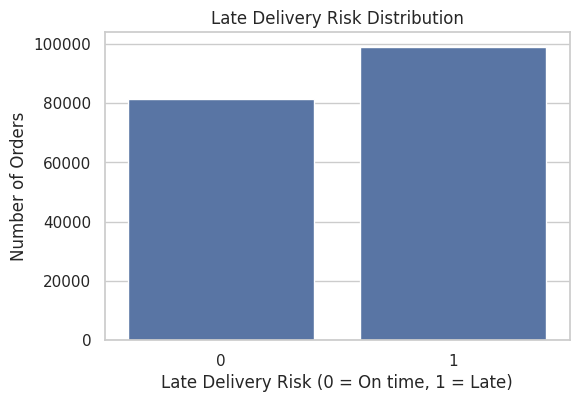


NUMERICAL FEATURES vs TARGET


Late_delivery_risk                             0           1
Days for shipment (scheduled) mean      3.491146    2.471069
                              median    4.000000    2.000000
                              std       1.151072    1.372540
Benefit per order             mean     22.403808   21.621707
                              median   31.680000   31.430000
                              std     103.163253  105.467754
Order Item Discount           mean     20.682753   20.649902
                              median   14.040000   14.000000
                              std      21.937552   21.687774
Order Item Discount Rate      mean      0.101637    0.101694
                              median    0.100000    0.090000
                              std       0.070179    0.070610
Order Item Product Price      mean    141.567424  140.956665
                              median   65.000000   59.990002
                              std     141.266639  138.455924
Order Item Profit Ratio       mean      0.121837    0.119666
                              median    0.270000    0.270000
                              std       0.464369    0.468786
Order Item Quantity           mean      2.127860    2.127454
                              median    1.000000    1.000000
                              std       1.453282    1.453598
Order Item Total              mean    183.609025  182.694518
                              median  163.990005  163.990005
                              std     121.428716  118.889507


Correlation with Target:


,Correlation
Days for shipment (scheduled),-0.369352
Order Item Total,-0.003791
Benefit per order,-0.003727
Order Item Profit Ratio,-0.002316
Order Item Product Price,-0.002175
Order Item Discount,-0.000750
Order Item Discount Rate,0.000404
Order Item Quantity,-0.000139


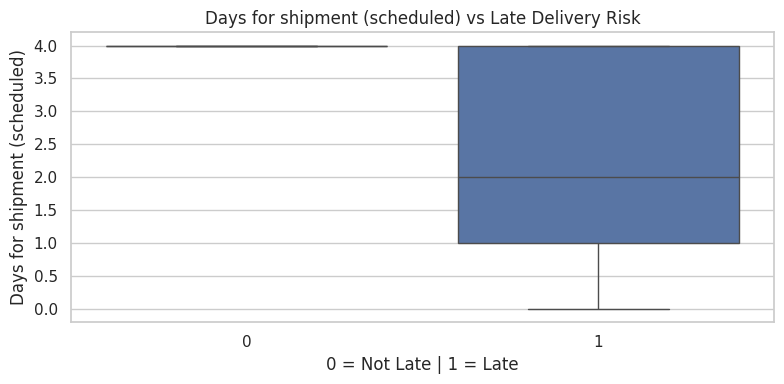

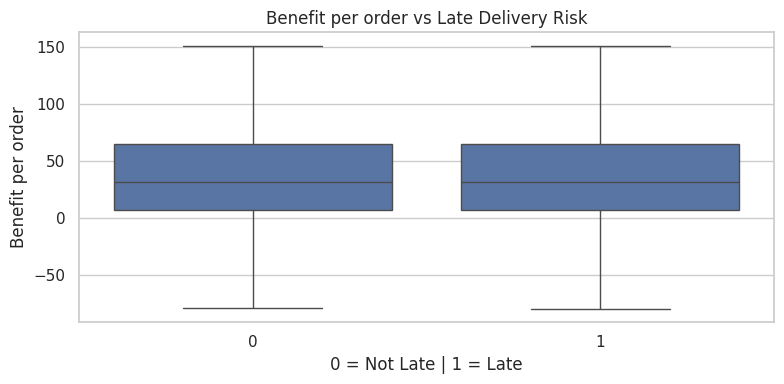

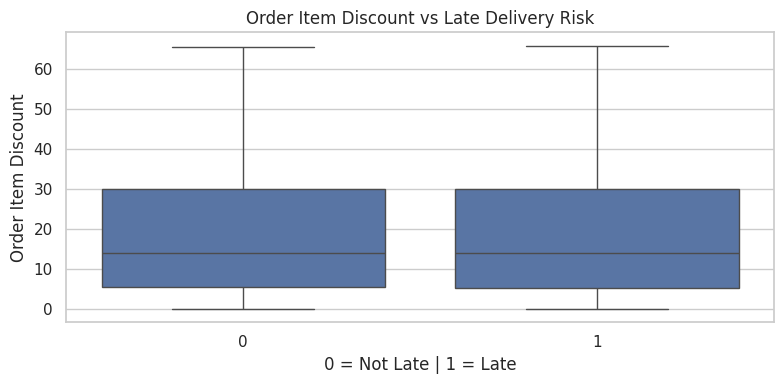

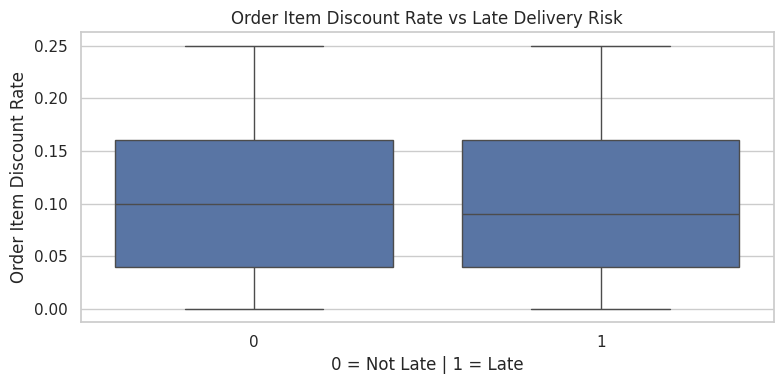

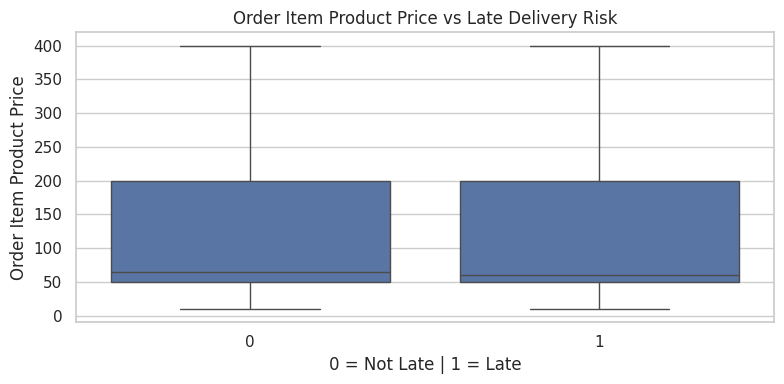

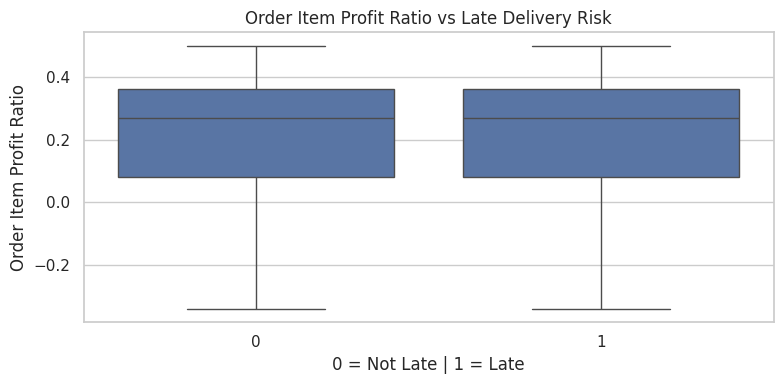

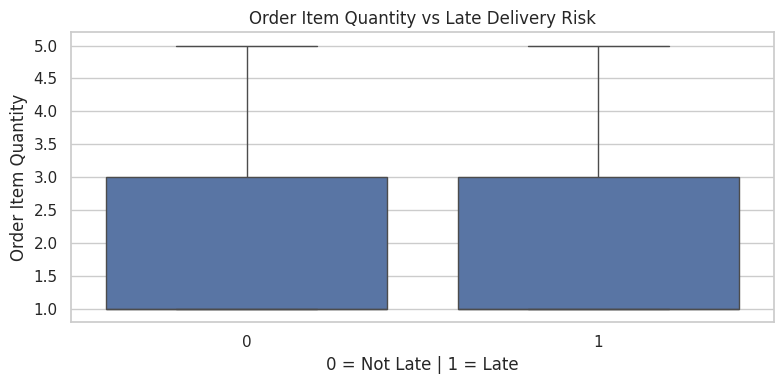

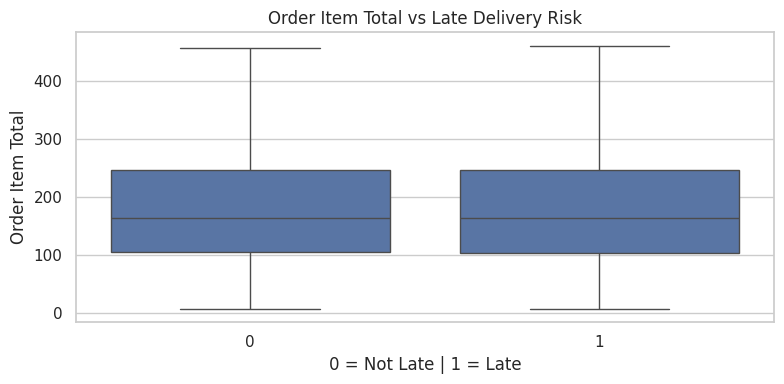


CATEGORICAL FEATURES vs TARGET

Feature: Type


,Orders,Late_Rate
Type,,
PAYMENT,41725,57.53
DEBIT,69295,57.22
CASH,19616,56.63
TRANSFER,49883,48.54


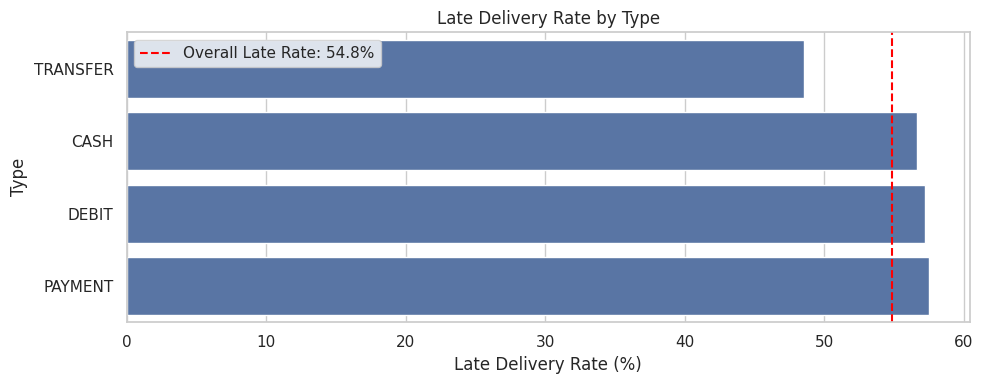


Feature: Category Name


,Orders,Late_Rate
Category Name,,
Lacrosse,343,60.06
Pet Supplies,492,58.94
Cameras,592,58.11
Strength Training,111,57.66
Music,434,57.14
Accessories,1780,56.97
Fitness Accessories,309,56.96
Books,405,56.54
Women's Clothing,650,56.46


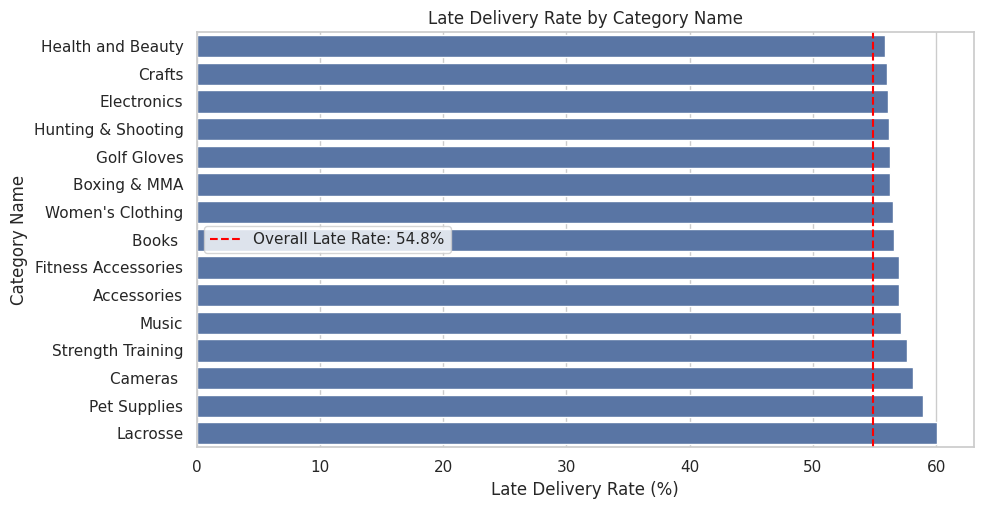


Feature: Customer Segment


,Orders,Late_Rate
Customer Segment,,
Home Office,32226,55.07
Consumer,93504,54.81
Corporate,54789,54.72


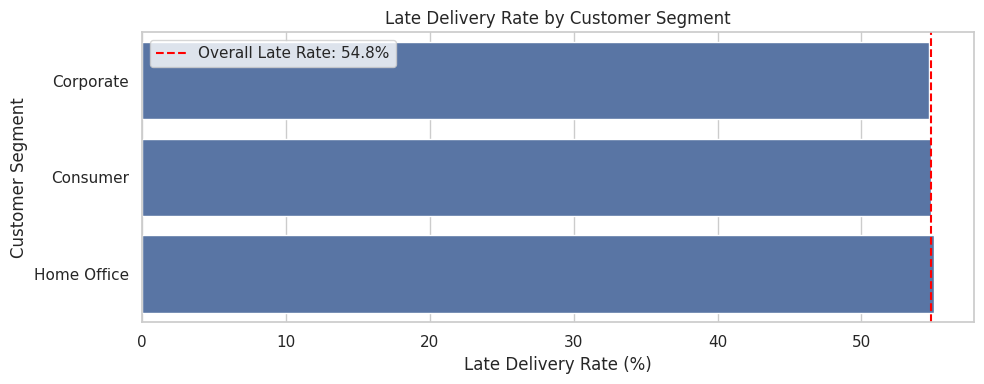


Feature: Department Name


,Orders,Late_Rate
Department Name,,
Pet Shop,492,58.94
Book Shop,405,56.54
Health and Beauty,362,55.80
Fitness,2479,55.55
Outdoors,9686,55.49
Technology,1465,55.02
Golf,33220,54.78
Fan Shop,66861,54.77
Apparel,48998,54.75


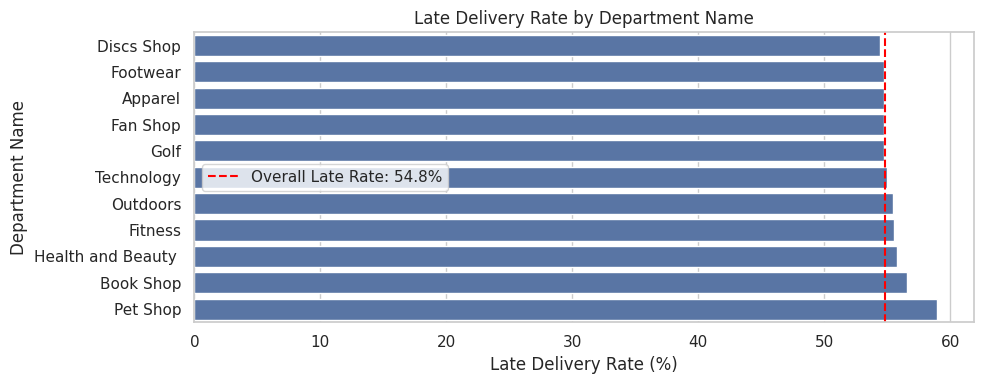


Feature: Market


,Orders,Late_Rate
Market,,
Europe,50252,55.21
Pacific Asia,41260,55.05
USCA,25799,54.80
Africa,11614,54.59
LATAM,51594,54.36


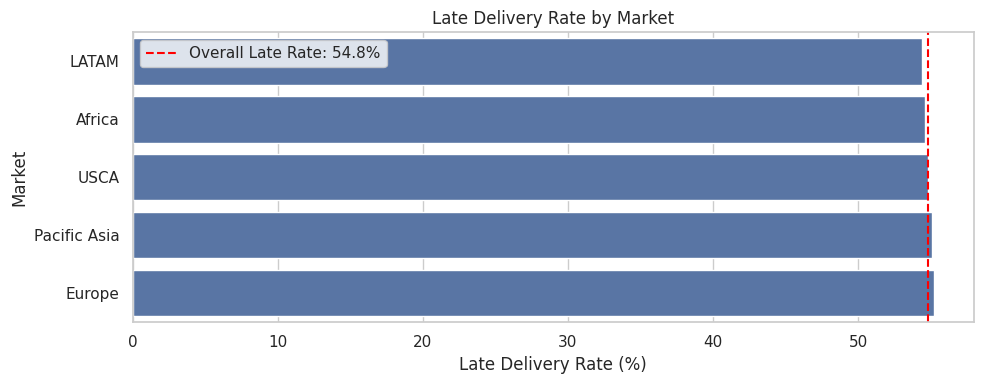


Feature: Order Country


,Orders,Late_Rate
Order Country,,
Ecuador,294,67.01
Mozambique,244,63.93
Níger,108,63.89
Somalia,141,63.83
Hungría,179,62.57
Malasia,544,61.21
Costa de Marfil,257,60.70
Irlanda,491,60.69
Ghana,264,60.61


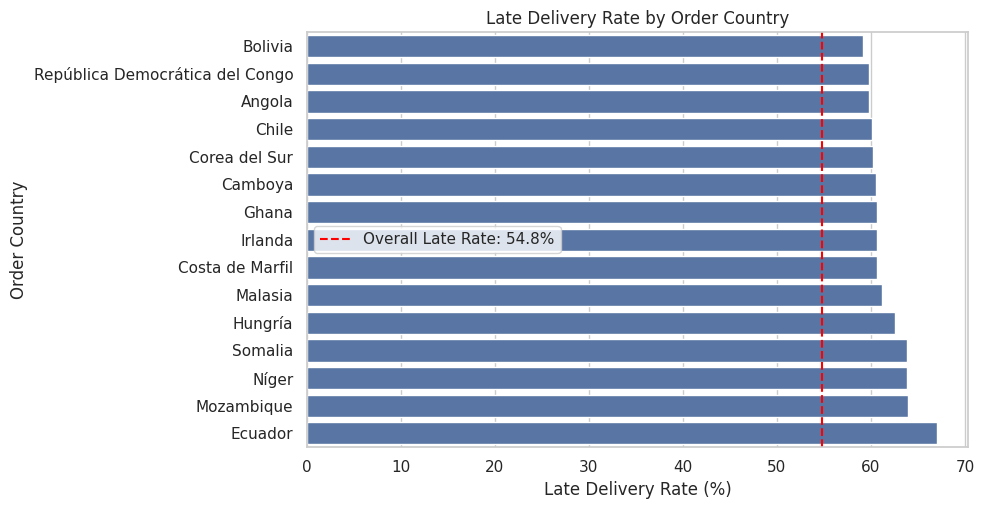


Feature: Order Region


,Orders,Late_Rate
Order Region,,
Central Africa,1677,57.96
South Asia,7731,56.27
East Africa,1852,55.94
Western Europe,27109,55.85
South of USA,4045,55.77
Eastern Europe,3920,55.66
East of USA,6915,55.66
Southeast Asia,9539,55.53
Central Asia,553,55.33


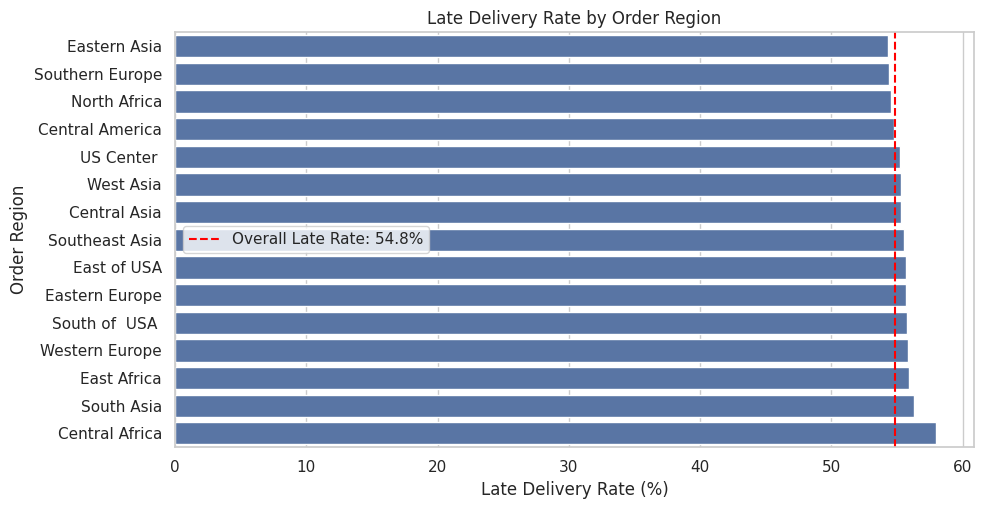


Feature: Shipping Mode


,Orders,Late_Rate
Shipping Mode,,
First Class,27814,95.32
Second Class,35216,76.63
Same Day,9737,45.74
Standard Class,107752,38.07


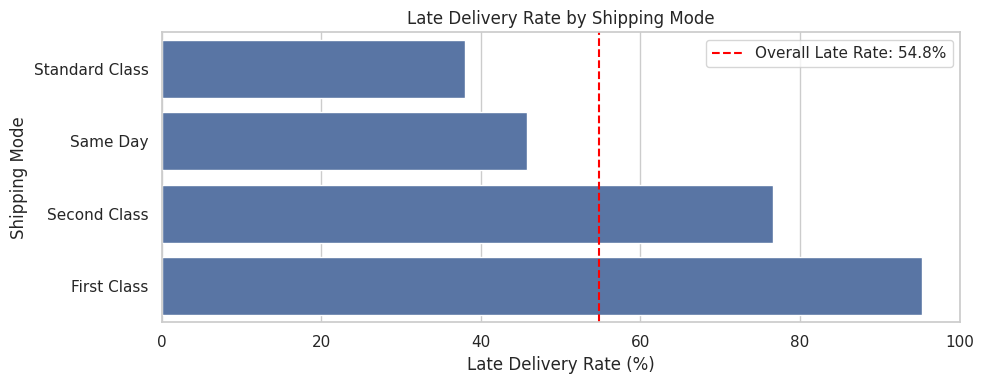


EDA COMPLETED
Total rows analyzed: 180,519
Numerical features: 8
Categorical features: 8
Overall late delivery rate: 54.83%


In [ ]:

# ==========================================
# EDA: FEATURES vs TARGET
# ==========================================

target = 'Late_delivery_risk'

if target not in df.columns:
    raise ValueError(f"{target} not found in dataframe")

# Make sure target is numeric
df[target] = pd.to_numeric(df[target], errors='coerce')

# Remove rows with missing target only
eda_df = df.dropna(subset=[target]).copy()

# ==========================================
# 1. TARGET DISTRIBUTION
# ==========================================

print("=" * 60)
print("TARGET DISTRIBUTION")
print("=" * 60)

target_counts = eda_df[target].value_counts().sort_index()
target_percentages = (
    eda_df[target].value_counts(normalize=True).sort_index() * 100
)

display(pd.DataFrame({
    'Count': target_counts,
    'Percentage': target_percentages.round(2)
}))

late_rate = (eda_df[target] == 1).mean() * 100

print(f"Overall Late Delivery Rate: {late_rate:.2f}%")

plt.figure(figsize=(6, 4))
sns.countplot(data=eda_df, x=target)
plt.title("Late Delivery Risk Distribution")
plt.xlabel("Late Delivery Risk (0 = On time, 1 = Late)")
plt.ylabel("Number of Orders")
plt.show()


# ==========================================
# 2. NUMERICAL FEATURES vs TARGET
# ==========================================

numerical_features = eda_df.select_dtypes(
    include=np.number
).columns.drop(target, errors='ignore').tolist()

print("\n" + "=" * 60)
print("NUMERICAL FEATURES vs TARGET")
print("=" * 60)

# Compare statistics between late and non-late orders
numeric_comparison = (
    eda_df.groupby(target)[numerical_features]
    .agg(['mean', 'median', 'std'])
    .T
)

display(numeric_comparison)

# Correlation with target
numeric_corr = (
    eda_df[numerical_features + [target]]
    .corr(numeric_only=True)[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

print("\nCorrelation with Target:")
display(numeric_corr.to_frame("Correlation"))

# Boxplots
for col in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=eda_df,
        x=target,
        y=col,
        showfliers=False
    )

    plt.title(f"{col} vs Late Delivery Risk")
    plt.xlabel("0 = Not Late | 1 = Late")
    plt.tight_layout()
    plt.show()


# ==========================================
# 3. CATEGORICAL FEATURES vs TARGET
# ==========================================

categorical_features = eda_df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Exclude raw date from categorical analysis for now
categorical_features = [
    col for col in categorical_features
    if col.lower() != 'order date (dateorders)'
]

print("\n" + "=" * 60)
print("CATEGORICAL FEATURES vs TARGET")
print("=" * 60)

for col in categorical_features:

    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")

    # Count and late delivery rate for each category
    category_analysis = (
        eda_df.groupby(col, dropna=False)
        .agg(
            Orders=(target, 'size'),
            Late_Rate=(target, 'mean')
        )
    )

    category_analysis['Late_Rate'] *= 100

    # Avoid drawing conclusions from very rare categories
    reliable_categories = category_analysis[
        category_analysis['Orders'] >= 100
    ].sort_values('Late_Rate', ascending=False)

    display(reliable_categories.round(2))

    if not reliable_categories.empty:

        plot_data = reliable_categories.head(15).sort_values(
            'Late_Rate'
        )

        plt.figure(figsize=(10, max(4, len(plot_data) * 0.35)))

        sns.barplot(
            x=plot_data['Late_Rate'],
            y=plot_data.index.astype(str)
        )

        plt.axvline(
            late_rate,
            linestyle='--',
            color='red',
            label=f'Overall Late Rate: {late_rate:.1f}%'
        )

        plt.title(f"Late Delivery Rate by {col}")
        plt.xlabel("Late Delivery Rate (%)")
        plt.ylabel(col)
        plt.legend()
        plt.tight_layout()
        plt.show()


# ==========================================
# 4. SUMMARY
# ==========================================

print("\n" + "=" * 60)
print("EDA COMPLETED")
print("=" * 60)

print(f"Total rows analyzed: {len(eda_df):,}")
print(f"Numerical features: {len(numerical_features)}")
print(f"Categorical features: {len(categorical_features)}")
print(f"Overall late delivery rate: {late_rate:.2f}%")


In [ ]:
# Select numerical features
numerical_features = df.select_dtypes(include=np.number)

# Calculate correlation matrix
corr_matrix = numerical_features.corr()

corr_matrix      # Due to this numbers we dropped sales column bec it has corr: 0.989 with Order Item Total

,Days for shipment (scheduled),Benefit per order,Late_delivery_risk,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Order Item Total
Days for shipment (scheduled),1.000000,-0.000185,-0.369352,0.002897,0.000065,0.006912,-0.001822,-0.002925,0.006445
Benefit per order,-0.000185,1.000000,-0.003727,0.064756,-0.018644,0.103459,0.823689,0.015696,0.133484
Late_delivery_risk,-0.369352,-0.003727,1.000000,-0.000750,0.000404,-0.002175,-0.002316,-0.000139,-0.003791
Order Item Discount,0.002897,0.064756,-0.000750,1.000000,0.659955,0.488101,-0.002788,0.065379,0.498734
Order Item Discount Rate,0.000065,-0.018644,0.000404,0.659955,1.000000,0.000345,-0.002691,-0.000028,-0.119469
Order Item Product Price,0.006912,0.103459,-0.002175,0.488101,0.000345,1.000000,-0.002043,-0.476232,0.781781
Order Item Profit Ratio,-0.001822,0.823689,-0.002316,-0.002788,-0.002691,-0.002043,1.000000,0.001128,-0.001439
Order Item Quantity,-0.002925,0.015696,-0.000139,0.065379,-0.000028,-0.476232,0.001128,1.000000,0.105413
Order Item Total,0.006445,0.133484,-0.003791,0.498734,-0.119469,0.781781,-0.001439,0.105413,1.000000


In [ ]:
# 8. PREPARE DATA FOR MODELING
# ==========================================

target = 'Late_delivery_risk'

df_model = df.copy()

if 'order date (DateOrders)' in df_model.columns:
    df_model['order date (DateOrders)'] = pd.to_datetime(
        df_model['order date (DateOrders)'], errors='coerce'
    )
    df_model['order_month'] = df_model['order date (DateOrders)'].dt.month
    df_model['order_day'] = df_model['order date (DateOrders)'].dt.day
    df_model['order_year'] = df_model['order date (DateOrders)'].dt.year
    df_model = df_model.drop(columns=['order date (DateOrders)'])

X = df_model.drop(columns=[target])
y = df_model[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Training rows: {len(X_train)}")
print(f"Testing rows: {len(X_test)}")
print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")

X.head()

Training rows: 144415
Testing rows: 36104
Numeric features: 11
Categorical features: 8


,Type,Days for shipment (scheduled),Benefit per order,Category Name,Customer Segment,Department Name,Market,Order Country,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Order Item Total,Order Region,Shipping Mode,order_month,order_day,order_year
0,DEBIT,4,91.250000,Sporting Goods,Consumer,Fitness,Pacific Asia,Indonesia,13.110000,0.04,327.75,0.29,1,314.640015,Southeast Asia,Standard Class,1,31,2018
1,TRANSFER,4,-249.089996,Sporting Goods,Consumer,Fitness,Pacific Asia,India,16.389999,0.05,327.75,-0.80,1,311.359985,South Asia,Standard Class,1,13,2018
2,CASH,4,-247.779999,Sporting Goods,Consumer,Fitness,Pacific Asia,India,18.030001,0.06,327.75,-0.80,1,309.720001,South Asia,Standard Class,1,13,2018
3,DEBIT,4,22.860001,Sporting Goods,Home Office,Fitness,Pacific Asia,Australia,22.940001,0.07,327.75,0.08,1,304.809998,Oceania,Standard Class,1,13,2018
4,PAYMENT,4,134.210007,Sporting Goods,Corporate,Fitness,Pacific Asia,Australia,29.500000,0.09,327.75,0.45,1,298.250000,Oceania,Standard Class,1,13,2018


## 4. Feature Engineering and Modeling Preparation

The dataset is prepared for modeling by defining the target, creating time-based features, and splitting the data into training and testing sets.


In [ ]:
# 9. ENCODING + MULTIPLE MODELS
# ==========================================

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        #class_weight='balanced',
        random_state=42
    ),
    'Decision Tree': DecisionTreeClassifier(
        random_state=42,
        #class_weight='balanced'
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        #class_weight='balanced',
        min_samples_leaf=2,
        n_jobs=-1
    )
}

results = []
fitted_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    result = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_test, y_prob)
    }
    results.append(result)
    fitted_models[name] = pipeline

    print(f"\n=== {name} ===")
    print(f"Accuracy:  {result['Accuracy']:.4f}")
    print(f"Precision: {result['Precision']:.4f}")
    print(f"Recall:    {result['Recall']:.4f}")
    print(f"F1:        {result['F1']:.4f}")
    print(f"ROC AUC:   {result['ROC_AUC']:.4f}")
    print(classification_report(y_test, y_pred, target_names=['On Time', 'Late']))
    print('Confusion Matrix:')
    print(confusion_matrix(y_test, y_pred))


=== Logistic Regression ===
Accuracy:  0.6965
Precision: 0.8359
Recall:    0.5555
F1:        0.6674
ROC AUC:   0.7437
              precision    recall  f1-score   support

     On Time       0.62      0.87      0.72     16308
        Late       0.84      0.56      0.67     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.71      0.69     36104
weighted avg       0.74      0.70      0.69     36104

Confusion Matrix:
[[14150  2158]
 [ 8800 10996]]

=== Decision Tree ===
Accuracy:  0.6614
Precision: 0.6905
Recall:    0.6932
F1:        0.6918
ROC AUC:   0.6580
              precision    recall  f1-score   support

     On Time       0.63      0.62      0.62     16308
        Late       0.69      0.69      0.69     19796

    accuracy                           0.66     36104
   macro avg       0.66      0.66      0.66     36104
weighted avg       0.66      0.66      0.66     36104

Confusion Matrix:
[[10158  6150]
 [ 6074 13722]]

=== Random Fore

## 5. Model Training and Benchmarking

Multiple classifier models are trained and compared using accuracy, precision, recall, F1 score, and ROC-AUC as performance measures.


In [ ]:
# 10. BEST MODEL SELECTION
# ==========================================

comparison_df = pd.DataFrame(results).sort_values(
    ['ROC_AUC'],
    ascending=[False],
    na_position='last'
)

display(comparison_df.round(4))

best_model_name = comparison_df.iloc[0]['Model']
best_model = fitted_models[best_model_name]

print(f"\nBest model selected: {best_model_name}")

#joblib.dump(best_model, 'best_late_delivery_model.pkl')
#print('Best model saved to best_late_delivery_model.pkl')

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
2,Random Forest,0.7083,0.8210,0.5985,0.6923,0.7788
0,Logistic Regression,0.6965,0.8359,0.5555,0.6674,0.7437
1,Decision Tree,0.6614,0.6905,0.6932,0.6918,0.6580



Best model selected: Random Forest


## 6. Hyperparameter Tuning and Final Selection

The best-performing model is selected using ROC-AUC as the primary metric, followed by threshold tuning and final validation on the test set.


In [ ]:
rf_model = fitted_models['Random Forest']

y_prob = rf_model.predict_proba(X_test)[:, 1]

thresholds = [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")

    print("Accuracy:", accuracy_score(y_test, y_pred_threshold))
    print("Precision:", precision_score(y_test, y_pred_threshold))
    print("Recall:", recall_score(y_test, y_pred_threshold))
    print("F1:", f1_score(y_test, y_pred_threshold))

    print(confusion_matrix(y_test, y_pred_threshold))



Threshold: 0.3
Accuracy: 0.5874695324617771
Precision: 0.5731860256793072
Recall: 0.969690846635684
F1: 0.720489434373006
[[ 2014 14294]
 [  600 19196]]

Threshold: 0.35
Accuracy: 0.6353866607578108
Precision: 0.614093036058354
Recall: 0.9015962820771873
F1: 0.7305771592304544
[[ 5092 11216]
 [ 1948 17848]]

Threshold: 0.4
Accuracy: 0.6798415688012409
Precision: 0.6804855602787151
Recall: 0.7844008890684987
F1: 0.7287574797606476
[[ 9017  7291]
 [ 4268 15528]]

Threshold: 0.45
Accuracy: 0.7035785508530911
Precision: 0.7608720596672404
Recall: 0.6699333198625985
F1: 0.7125127598989953
[[12140  4168]
 [ 6534 13262]]

Threshold: 0.5
Accuracy: 0.7082871703966319
Precision: 0.820997920997921
Recall: 0.5984542331784198
F1: 0.6922807222579326
[[13725  2583]
 [ 7949 11847]]

Threshold: 0.55
Accuracy: 0.7046310658098826
Precision: 0.8457519309404816
Recall: 0.5642048898767428
F1: 0.676868068601903
[[14271  2037]
 [ 8627 11169]]

Threshold: 0.6
Accuracy: 0.7012796366053623
Precision: 0.85738082

In [ ]:
# ==========================================
# 1. CROSS VALIDATION
# ==========================================

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# ==========================================
# 2. RANDOM FOREST PIPELINE
# ==========================================

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        max_samples=0.8,
        random_state=42,
        n_jobs=1
    ))
])

# ==========================================
# 3. SEARCH SPACE
# ==========================================

param_distributions = {
    'model__n_estimators': [100, 150],
    'model__max_depth': [12, 20],
    'model__min_samples_split': randint(2, 16),
    'model__min_samples_leaf': randint(2, 9),
    'model__max_features': ['sqrt', 0.5],
    'model__class_weight': [
        None,
        'balanced'
    ]
}

# ==========================================
# 4. RANDOMIZED SEARCH
# ==========================================

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=8,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=2,
    pre_dispatch=2,
    verbose=2,
    refit=True
)

print("Starting Hyperparameter Tuning...")

random_search.fit(X_train, y_train)

print("\n===== BEST PARAMETERS =====")
print(random_search.best_params_)

print("\nBest CV ROC-AUC:")
print(random_search.best_score_)

# ==========================================
# 5. OUT-OF-FOLD PREDICTIONS
# ==========================================

best_model = random_search.best_estimator_

print("\nGenerating OOF Predictions...")

oof_prob = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

# ==========================================
# 6. THRESHOLD SELECTION
# ==========================================

thresholds = np.arange(0.20, 0.71, 0.01)

threshold_results = []

for threshold in thresholds:

    y_oof_pred = (oof_prob >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_train, y_oof_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_train, y_oof_pred, zero_division=0
        ),
        'F1': f1_score(
            y_train, y_oof_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

best_threshold = threshold_df.loc[
    threshold_df['F1'].idxmax(), 'Threshold'
]

print("\n===== TOP 10 THRESHOLDS =====")

print(
    threshold_df.sort_values(
        'F1', ascending=False
    ).head(10).round(4)
)

print("\nSelected Threshold:", best_threshold)

# ==========================================
# 7. FINAL TEST EVALUATION
# ==========================================

# random_search refit=True already trained
# the best model on the complete training set.
# No need to fit it again.

y_test_prob = best_model.predict_proba(X_test)[:, 1]

y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)

print("\n===== FINAL TEST RESULTS =====")

print("Threshold:", best_threshold)

print("Accuracy:",
      accuracy_score(y_test, y_test_pred))

print("Precision:",
      precision_score(y_test, y_test_pred))

print("Recall:",
      recall_score(y_test, y_test_pred))

print("F1:",
      f1_score(y_test, y_test_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, y_test_prob))

print("PR-AUC:",
      average_precision_score(y_test, y_test_prob))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=['On Time', 'Late'],
    zero_division=0
))

print("\nConfusion Matrix:")

print(confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
))

# ==========================================
# 8. SAVE MODEL
# ==========================================

fitted_models['Tuned Random Forest'] = best_model


Starting Hyperparameter Tuning...
Fitting 3 folds for each of 8 candidates, totalling 24 fits

===== BEST PARAMETERS =====
{'model__class_weight': 'balanced', 'model__max_depth': 20, 'model__max_features': 0.5, 'model__min_samples_leaf': 3, 'model__min_samples_split': 13, 'model__n_estimators': 100}

Best CV ROC-AUC:
0.7626303657263112

Generating OOF Predictions...

===== TOP 10 THRESHOLDS =====
    Threshold  Precision  Recall      F1
13       0.33     0.6087  0.8826  0.7205
14       0.34     0.6295  0.8418  0.7203
12       0.32     0.5949  0.9114  0.7199
11       0.31     0.5860  0.9312  0.7193
10       0.30     0.5794  0.9458  0.7186
15       0.35     0.6574  0.7906  0.7179
9        0.29     0.5737  0.9569  0.7174
8        0.28     0.5686  0.9663  0.7159
7        0.27     0.5637  0.9751  0.7144
6        0.26     0.5596  0.9822  0.7130

Selected Threshold: 0.3300000000000001

===== FINAL TEST RESULTS =====
Threshold: 0.3300000000000001
Accuracy: 0.6313981830268114
Precision: 0.61095

In [ ]:
# Create a folder for saved model files
os.makedirs("models", exist_ok=True)

# Save the complete pipeline
joblib.dump(best_model, "models/late_delivery_pipeline.pkl")

# Save the selected threshold
joblib.dump(0.33, "models/decision_threshold.pkl")

print("Model pipeline and threshold saved successfully!")

Model pipeline and threshold saved successfully!
